In [41]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base_model.trainable = False

154 False


In [23]:
inputs = tf.keras.Input(shape=(224, 224, 3))
x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)
x = base_model(x, training=False)                 
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(4, activation="softmax")(x)

tl_model = tf.keras.Model(inputs, outputs)
tl_model.summary()

Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [24]:
tl_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [25]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint("tl_best.keras", monitor="val_loss", save_best_only=True),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.BackupAndRestore("backup_tl"),
]

start = time.time()
history_tl = tl_model.fit(train_ds, validation_data=val_ds, epochs=20,
                          class_weight=class_weight, callbacks=callbacks)
tl_time = time.time() - start
print(f"Training time: {tl_time:.0f}s")

Epoch 1/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.5839 - loss: 0.9982

2026-10-28 02:42:51.107282: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1173', 636 bytes spill stores, 636 bytes spill loads

2026-10-28 02:42:51.288093: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1173', 884 bytes spill stores, 884 bytes spill loads



159/159 ━━━━━━━━━━━━━━━━━━━━ 44s 168ms/step - accuracy: 0.7130 - loss: 0.7173 - val_accuracy: 0.8114 - val_loss: 0.4775
Epoch 2/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 16s 98ms/step - accuracy: 0.8346 - loss: 0.4500 - val_accuracy: 0.7935 - val_loss: 0.5526
Epoch 3/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 20s 94ms/step - accuracy: 0.8527 - loss: 0.4008 - val_accuracy: 0.8292 - val_loss: 0.4344
Epoch 4/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 15s 96ms/step - accuracy: 0.8693 - loss: 0.3599 - val_accuracy: 0.8761 - val_loss: 0.3403
Epoch 5/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 15s 95ms/step - accuracy: 0.8693 - loss: 0.3521 - val_accuracy: 0.8728 - val_loss: 0.3449
Epoch 6/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 15s 95ms/step - accuracy: 0.8750 - loss: 0.3339 - val_accuracy: 0.8683 - val_loss: 0.3429
Epoch 7/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 15s 96ms/step - accuracy: 0.8813 - loss: 0.3222 - val_accuracy: 0.8739 - val_loss: 0.3203
Epoch 8/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 14s 90ms/step - accuracy: 0.8817 - loss: 0.3188 - val_accura

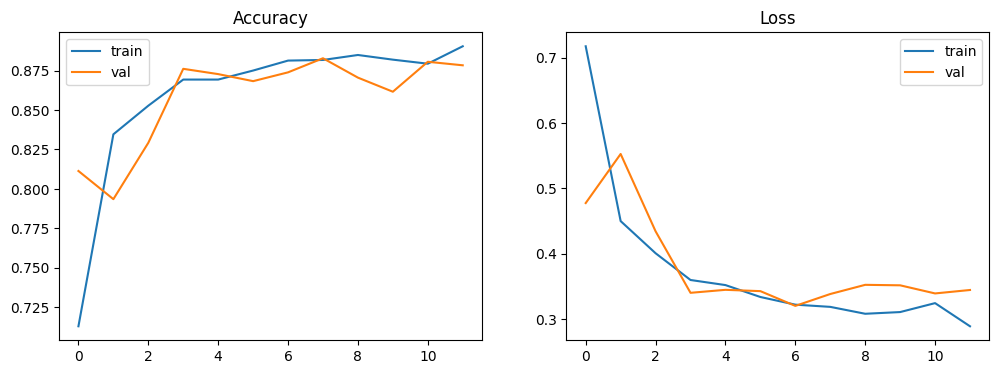

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history_tl.history["accuracy"], label="train")
ax[0].plot(history_tl.history["val_accuracy"], label="val")
ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(history_tl.history["loss"], label="train")
ax[1].plot(history_tl.history["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].legend()
plt.show()

In [31]:
test_loss_tl, test_acc_tl = tl_model.evaluate(test_ds)
print(test_loss_tl, test_acc_tl)

31/33 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9505 - loss: 0.1187

2026-10-28 02:54:54.145651: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1173', 644 bytes spill stores, 644 bytes spill loads

2026-10-28 02:54:54.467045: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1173', 852 bytes spill stores, 852 bytes spill loads



33/33 ━━━━━━━━━━━━━━━━━━━━ 10s 318ms/step - accuracy: 0.9497 - loss: 0.1304
0.130399689078331 0.9497153759002686


In [32]:
from sklearn.metrics import confusion_matrix, classification_report, f1_score

y_pred_tl = np.argmax(tl_model.predict(test_ds), axis=1)
print(classification_report(y_test, y_pred_tl, target_names=CLASSES))
print(confusion_matrix(y_test, y_pred_tl))

33/33 ━━━━━━━━━━━━━━━━━━━━ 11s 191ms/step
              precision    recall  f1-score   support

      glioma       0.99      0.93      0.96       243
  meningioma       0.92      0.89      0.90       247
     notumor       0.99      0.97      0.98       300
   pituitary       0.90      1.00      0.95       264

    accuracy                           0.95      1054
   macro avg       0.95      0.95      0.95      1054
weighted avg       0.95      0.95      0.95      1054

[[227  13   0   3]
 [  2 219   2  24]
 [  1   5 292   2]
 [  0   1   0 263]]
